In [1]:
#Load all the packages I might need
from __future__ import division # must be first
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib import rc
import matplotlib.gridspec as gridspec
from matplotlib.figure import Figure
import matplotlib
from matplotlib import rc
from scipy.io import loadmat
from scipy.integrate import odeint
from scipy.integrate import quad
from mpmath import gammainc
import numbers
import pickle
from scipy.stats import dirichlet
from tqdm import tqdm
import matplotlib.patches as mpatches
from scipy.spatial.distance import jensenshannon
import pandas as pd
import os
from matplotlib.path import Path
import matplotlib.ticker as ticker
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl


def is_real_number(num):
  return isinstance(num, numbers.Number)


from scipy.special import gamma, gammaincc, expn

from scipy.optimize import curve_fit
#plt.rcParams['text.usetex'] = True
#rc('font', **{'family': 'serif', 'serif': ['Arial']})
#plt.rc('font', family='sans-serif', sans-serif=['Arial'])
rc('font', **{'family': 'sans-serif', 'sans-serif': ['Arial']})
plt.style.use('Leighton_Style_Colors2')

mpl.rcParams.update({
    "text.usetex": False,          # turn off LaTeX
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],  # try Arial first, then fallbacks
})

mpl.rcParams["xtick.labelsize"] = 8
mpl.rcParams["ytick.labelsize"] = 8


In [2]:
##### Load and interpret the 6-state cooling data

pi_dist = np.array([0.1154,0.1807,0.1383,0.1271,0.2776,0.1609])

import pickle
import numpy as np
import matplotlib.pyplot as plt

# Load the data (replace with your actual file path)
with open('particle_assignments.pkl', 'rb') as file:
    data = pickle.load(file)

# Get all simulation time lengths and sort them
time_lengths = sorted(data.keys())

# Find all unique states across all simulations
all_states = set()
for time_length in time_lengths:
    states = data[time_length][:, 0]
    all_states.update(states)
all_states = sorted(all_states)

# Calculate the fraction of each state for each time length
fractions = {}
for state in all_states:
    fractions[state] = []
    for time_length in time_lengths:
        states = data[time_length][:, 0]
        # Count occurrences of this state
        count = np.sum(states == state)
        # Calculate fraction
        fraction = count / len(states)
        fractions[state].append(fraction)



In [5]:
##### Energy Function for later

def V(x, y, z=0.0):
    """
    2D potential with:
      • 6 Gaussian wells (including a central well)
      • no central bump (height = 0)
      • a quadratic repulsive barrier beyond r = 1.5
      • z-confinement 1000·z²
    """
    # Harmonic confinement in z
    V = 1000.0 * z**2

    # Gaussian wells: (xi, yi), Ai, wi
    V += (-27.5) * np.exp(-3.0 * ((x - 1.25)**2 + (y - 0.25)**2))
    V += (-30.0)  * np.exp(-6.0 * ((x - 0.75)**2 + (y - 1.0 )**2))
    V += (-35.0)  * np.exp(-4.0 * ((x + 0.75)**2 + (y - 1.5 )**2))
    V += (-30.0)  * np.exp(-6.0 * ((x + 1.00)**2 + (y + 0.5 )**2))
    V += (-35.0)  * np.exp(-5.0 * ((x + 0.50)**2 + (y + 1.25)**2))
    V += (-30.0)  * np.exp(-3.0 * ((x - 0.00)**2 + (y - 0.00)**2))  # central well

    # (No central bump: center_bump_height = 0)

    # Radial repulsive barrier: only when r > 1.5
    r = np.hypot(x, y)
    V += np.where(
        r > 1.5,
        100.0 * (r - 1.5)**2,
        0.0
    )

    return V

In [9]:
##### Plotting Helper Functions for Fig b:


def make_snowflake_path(
    n_arms=6,            # number of main arms (typical snowflake uses 6)
    R=1.0,               # main arm length (relative)
    branch_at=0.55,      # where along the arm the side branches start (0..1)
    branch_len=0.35,     # length of side branches (relative to R)
    branch_angle_deg=30, # angle of side branches from the arm direction
    hub=0.12             # radius of a small central hub (0 to disable)
):
    verts, codes = [], []
    for i in range(n_arms):
        theta = i * 2 * np.pi / n_arms

        # main arm
        x0, y0 = 0.0, 0.0
        x1, y1 = R * np.cos(theta), R * np.sin(theta)
        verts += [(x0, y0), (x1, y1)]
        codes += [Path.MOVETO, Path.LINETO]

        # side branches on each arm (± branch_angle)
        xb, yb = branch_at * R * np.cos(theta), branch_at * R * np.sin(theta)
        for sgn in (+1, -1):
            phi = theta + sgn * np.deg2rad(branch_angle_deg)
            x2, y2 = xb + branch_len * np.cos(phi), yb + branch_len * np.sin(phi)
            verts += [(xb, yb), (x2, y2)]
            codes += [Path.MOVETO, Path.LINETO]

    # optional small hub polygon to make the center look finished
    if hub > 0:
        for i in range(n_arms):
            ang = i * 2 * np.pi / n_arms
            p = (hub * np.cos(ang), hub * np.sin(ang))
            if i == 0:
                verts.append(p); codes.append(Path.MOVETO)
            else:
                verts.append(p); codes.append(Path.LINETO)
        verts.append((0.0, 0.0)); codes.append(Path.CLOSEPOLY)

    # normalize to unit radius so marker sizing behaves as expected
    arr = np.asarray(verts, dtype=float)
    m = np.max(np.hypot(arr[:,0], arr[:,1]))
    if m > 0:
        arr /= m

    return Path(arr, codes)

snowflake_path = make_snowflake_path()

from matplotlib.patches import FancyArrowPatch

def add_parallel_arrow(x, y, idx=None, span=1, offset=0.02, frac=0.6, ax=None, **kw):
    """
    Draw an arrow parallel to the polyline (x,y), shifted to the right.
    idx:   starting vertex index to set the direction
    span:  use segment [idx, idx+span] to define orientation
    offset: perpendicular shift (in data units)
    frac:  fraction of the chosen segment length to draw as arrow
    """
    if ax is None: ax = plt.gca()
    x = np.asarray(x); y = np.asarray(y)
    if idx is None:
        idx = max(0, len(x)//2 - 1)
    j = min(len(x)-1, idx+span)

    # direction vector along the polyline
    vx, vy = x[j] - x[idx], y[j] - y[idx]
    L = np.hypot(vx, vy)
    if L == 0: return
    ux, uy = vx / L, vy / L

    # normal vector; choose sign so the shift increases x (i.e., moves "right")
    nx, ny = -uy, ux
    if (x[idx] + offset*nx) < x[idx]:
        nx, ny = -nx, -ny

    # start & end of the arrow, shifted to the right of the line
    start = (x[idx] + offset*nx, y[idx] + offset*ny)
    end   = (start[0] + frac*L*ux, start[1] + frac*L*uy)

    arr = FancyArrowPatch(start, end, arrowstyle='-|>',
                          mutation_scale=12, lw=1, color='black',
                          alpha=1, clip_on=False, **kw)
    ax.add_patch(arr)

###Data for panel b:
tau_list_6state = np.array([1000,5000,10000,50000,100000,500000,1000000,5000000,10000000,50000000])

p1_list = np.array(fractions[1])
p2_list = np.array(fractions[2])
p3_list = np.array(fractions[3])
p4_list = np.array(fractions[4])
p5_list = np.array(fractions[5])
p6_list = np.array(fractions[6])

pi_dist = np.array([0.1154,0.1807,0.1383,0.1271,0.2776,0.1609])

T_h = 500
T_c = 100
pi_c_dist = pi_dist**(T_h/T_c)/np.sum(pi_dist**(T_h/T_c))

inference = np.load('Inference_Results/figure_data.npz')
mean_2, mean_5 = inference['allowed_mean'][[1, 4]]

std_2, std_5 = inference['allowed_std'][[1, 4]]

list_2 = np.linspace(mean_2-std_2,mean_2+std_2,num=100)

In [11]:
def format_axes(ax, minor_ticks_x=2, minor_ticks_y=2,
                stroke_in=0.01):
    lw = stroke_in * 72  # convert to points
    ax.minorticks_on()
    if ax.get_xscale() == 'log':
        ax.xaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_x))
    if ax.get_yscale() == 'log':
        ax.yaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_y))
    # spines
    for spine in ax.spines.values():
        spine.set_linewidth(lw)
        spine.set_color('black')
    # tick parameters
    ax.tick_params(which='major', width=lw, length=4.5, direction='in',
                   top=True, bottom=True, left=True, right=True)
    ax.tick_params(which='minor', width=lw * 0.75, length=2.25, direction='in',
                   top=True, bottom=True, left=True, right=True)
    return ax


In [13]:
import matplotlib.ticker as ticker
import matplotlib

def format_axes_histogram(ax, minor_ticks_x=2, minor_ticks_y=2,
                          stroke_in=0.01):
    lw = stroke_in * 72  # convert to points

    # 1) Start with minor ticks OFF everywhere
    ax.minorticks_off()

    # 2) Turn ON minor ticks only for y-axis
    if ax.get_yscale() == 'log':
        ax.yaxis.set_minor_locator(ticker.LogLocator(subs='auto'))
    else:
        ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(minor_ticks_y))
    # (x-axis keeps its default NullLocator -> no minor ticks on x)

    # 3) Spines
    for spine in ax.spines.values():
        spine.set_linewidth(lw)
        spine.set_color('black')

    # 4) Major ticks: we’ll allow bottom, left, right here
    ax.tick_params(which='major', width=lw, length=4.5, direction='in',
                   top=True, bottom=True, left=True, right=True)

    # 5) Minor ticks: these settings apply to y (since x has no minor locs)
    ax.tick_params(which='minor', width=lw * 0.75, length=2.25, direction='in',
                   top=True, bottom=True, left=True, right=True)

    # 6) Make sure x-axis has NO minor tick labels (not really needed,
    #     but safe if you ever add a minor locator later)
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    #ax.xaxis.set_major_formatter(matplotlib.ticker.NullFormatter())
    
    # 7) Turn OFF all top ticks (major + minor) on the x-axis
    ax.tick_params(axis='x', which='both',
               top=False,      # no tick marks at top
               bottom=False,   # no tick marks at bottom
               labelbottom=True)  # but keep the labels at the bottom

    # Optional: if you also want no top border line:
    # ax.spines['top'].set_visible(False)

    return ax


In [15]:
### Data for panel F:
DKL_list = inference['single_condition_kl_to_equilibrium']
DKL_2_list = inference['cooled_kl_to_equilibrium']

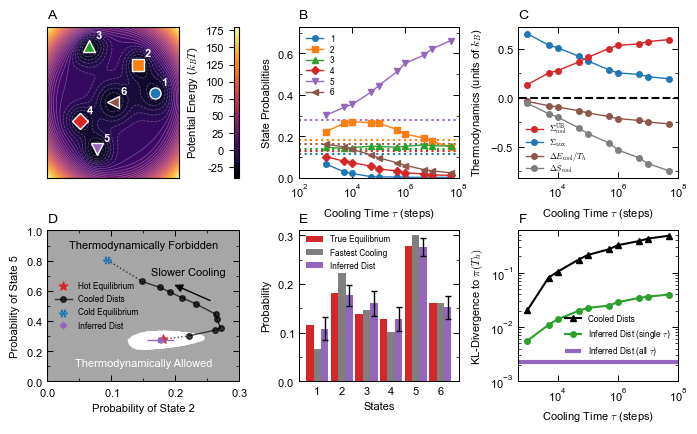

In [17]:
# Set up the figure
width = 8.6
height = 7
fig = plt.figure(figsize=(17.8/2.54, 10/2.54))


# Create subplot layout (1 row, 3 columns)
gs = gridspec.GridSpec(2, 3, figure=fig, width_ratios=[1.2, 1, 1], wspace=0.35,hspace=0.35)



# ============================================================================
# PANEL A: Energy Landscape
# ============================================================================
#ax1 = fig.add_subplot(gs[0, 0])


# Split the cell gs[0, 0] into two columns: [heatmap | colorbar]
gsA = gridspec.GridSpecFromSubplotSpec(
    1, 2, subplot_spec=gs[0, 0],
    width_ratios=[30, 1],   # A narrower colorbar; adjust as you like
    wspace=0.25
)

ax1  = fig.add_subplot(gsA[0, 0])  # main panel A
cax1 = fig.add_subplot(gsA[0, 1])  # dedicated colorbar axes


# Create a grid of x,y coordinates
x_range = np.linspace(-2, 2, 200)
y_range = np.linspace(-2, 2, 200)
X, Y = np.meshgrid(x_range, y_range)

markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*']
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown']

# Calculate potential values at each grid point
Z = V(X, Y)

# Create the heatmap
contour = ax1.contourf(X, Y, Z, levels=50, cmap='inferno')

# Add contour lines for better visualization
ax1.contour(X, Y, Z, levels=50, colors='white', alpha=0.3, linewidths=0.5)

# Mark the well positions
well_positions = [
    (1.25, 0.25),   # Well 1
    (0.75, 1.0),    # Well 2
    (-0.75, 1.5),   # Well 3
    (-1.00, -0.5),  # Well 4
    (-0.50, -1.25), # Well 5
    (0.0, 0.0)      # Central well
]

for i, (x_well, y_well) in enumerate(well_positions):
    ax1.plot(x_well, y_well, marker=markers[i], markersize=8, color=colors[i],markeredgecolor='white', markeredgewidth=1)
    ax1.text(x_well + 0.2, y_well + 0.2, f'{i+1}', color='white', fontweight='bold',fontsize=8)

ax1.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False) # labels along the bottom edge are off

ax1.tick_params(
    axis='y',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    left=False,      # ticks along the bottom edge are off
    right=False,         # ticks along the top edge are off
    labelleft=False) # labels along the bottom edge are off

#ax1.set_xlabel('x')
#ax1.set_ylabel('y')
ax1.set_xlim(-2,2)
ax1.set_ylim(-2,2)

cbar = fig.colorbar(contour, cax=cax1, label=r'Potential Energy ($k_BT$)',format=ticker.FormatStrFormatter('%.0f'),fraction=0.03,pad=0.2)

cbar.ax.yaxis.label.set_size(8) 
cbar.ax.yaxis.set_label_position('left')
cbar.ax.yaxis.set_ticks_position('left')

box = ax1.get_position()  # [x0, y0, width, height] in figure coords
ax1.set_position([box.x0, box.y0, box.width * 0.8, box.height])


# ============================================================================
# PANEL B: Probability Evolution
# ============================================================================
ax2 = fig.add_subplot(gs[0, 1])

# Plot fraction for each state with different colors and markers
markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p', '*']
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown']
for i, state in enumerate(all_states):
    marker = markers[i % len(markers)]
    ax2.plot(time_lengths, fractions[state], marker=marker, linewidth=1, 
             label=f'{int(state)}', markersize=4, color=colors[i],zorder=2,ls='-')
    ax2.hlines(pi_dist[i],100,100000000,ls=':',color=colors[i],lw=1.5,zorder=1)

# Set logarithmic scale for x-axis since time lengths span orders of magnitude
ax2.set_xscale('log')

# Add labels and title
ax2.set_xlabel(r"Cooling Time $\tau$ (steps)", fontsize=8)
ax2.set_ylabel('State Probabilities', fontsize=8)
#plt.title('Distribution of States as a Function of Simulation Time Length', fontsize=16)
ax2.legend(fontsize=6,frameon=False,loc='upper left',bbox_to_anchor=(0, 1.0),labelspacing=0.2)
ax2.set_xlim(100,100000000)

# Improve appearance
ax2.set_ylim(0, max([max(fractions[state]) for state in all_states]) * 1.1)  # Add 10% margin at top


# ============================================================================
# PANEL C: Thermodynamics
# ============================================================================
ax3 = fig.add_subplot(gs[0, 2])

EP_UB_list = inference['cooling_entropy_production']
Delta_energy_list = inference['cooling_energy_change']
Delta_entropy_list = inference['cooling_entropy_change']
EP_aux_list = inference['auxiliary_entropy_production']


ax3.plot(time_lengths,EP_UB_list,color='tab:red',marker='o',markersize=4,ls='-',label=r'$\Sigma_\mathrm{cool}^\mathrm{UB}$',zorder=10,lw=1)
ax3.plot(time_lengths,EP_aux_list,color='tab:blue',marker='o',markersize=4,ls='-',label=r'$\Sigma_\mathrm{aux}$',lw=1)

#ax4.plot(tau_list,EP_aux_list,color='tab:blue',marker='o',markersize=10,ls='-',label=r'$\Sigma_\mathrm{aux}$ (auxiliary relaxation)')

ax3.plot(time_lengths,Delta_energy_list,color='tab:brown',marker='o',markersize=4,ls='-',label=r'$\Delta E_\mathrm{cool}/T_h$',lw=1)
ax3.plot(time_lengths,Delta_entropy_list,color='tab:grey',marker='o',markersize=4,ls='-',label=r'$\Delta S_\mathrm{cool}$',lw=1)


ax3.set_xlabel(r"Cooling Time $\tau$ (steps)",fontsize=8)
ax3.set_ylabel(r'Thermodynamics (units of $k_B$)',fontsize=8)
#ax4.set_ylim(0,0.035)
#ax4.set_xlim(7, 2000)
ax3.set_xscale('log')
ax3.legend(loc='lower left',frameon=False,fontsize=6,bbox_to_anchor=(0, -0.03),labelspacing=0.1)
ax3.hlines(0, 0.1*min(time_lengths), 10*max(time_lengths), color='black', linestyle='--', linewidth=1.5)
ax3.set_xlim(0.5*time_lengths[0], 2*time_lengths[-1])


# ============================================================================
# PANEL D: Schematic/Demonstration
# ============================================================================
ax4 = fig.add_subplot(gs[1, 0])

ax4.fill_between(np.linspace(0,1,100),np.zeros(100),np.ones(100),color='grey',alpha=0.7)

distributions = inference['allowed_probabilities']
ax4.scatter(distributions[:, 1], distributions[:, 4], s=3,color='white')


ax4.errorbar(mean_2,mean_5,xerr=std_2,yerr=std_5,marker='s',markersize=3,color='tab:purple',alpha=1,elinewidth=1,zorder=11,label=r'Inferred Dist',lw=0)

ax4.plot([pi_c_dist[1],p2_list[-1]],[pi_c_dist[4],p5_list[-1]],color='black',ls=':',marker='none',alpha=0.7,lw=1,zorder=9)
ax4.plot([pi_dist[1],p2_list[0]],[pi_dist[4],p5_list[0]],color='black',ls=':',marker='none',alpha=0.7,lw=1,zorder=9)

ax4.scatter(pi_dist[1],pi_dist[4],marker='*',color='tab:red',s=40,zorder=10,label=r'Hot Equilibrium')
ax4.plot(p2_list,p5_list,marker='o',color='black',markersize=4,ls='-',lw=1,alpha=0.7,label=r'Cooled Dists')

ax4.scatter(pi_c_dist[1],pi_c_dist[4],marker=snowflake_path,color='tab:blue',s=40,zorder=10,label=r'Cold Equilibrium')

add_parallel_arrow(p2_list, p5_list, idx=len(p2_list)//2, span=1, offset=0.03, frac=3)
ax4.text(0.22,0.7,'Slower Cooling',ha='center',color='black',fontsize=8,zorder=10)


#plt.xlim(0,0.3)
#plt.ylim(0.2,0.9)
ax4.set_xlim(0,0.3)
ax4.set_ylim(0,1)
ax4.text(0.15,0.88,'Thermodynamically Forbidden',ha='center',color='black',fontsize=8,zorder=8)
ax4.text(0.15,0.1,'Thermodynamically Allowed',ha='center',color='white',fontsize=8,zorder=8)
ax4.set_xlabel('Probability of State 2',fontsize=8)
ax4.set_ylabel('Probability of State 5',fontsize=8)
ax4.legend(loc='center left',fontsize=6,frameon=False)


# ============================================================================
# PANEL E: Histograms
# ============================================================================
ax5 = fig.add_subplot(gs[1, 1])
states = ['1', '2', '3', '4', '5', '6']
# Mean probability guesses for each state
mean_guesses = inference['allowed_mean']
# True distribution
true_distribution = inference['true_equilibrium']
fast_cool_dist = inference['cooled_probabilities'][0]
pi_dist = true_distribution.copy()
means = inference['allowed_mean']
stds = inference['allowed_std']

T_h = 500
T_c = 100

# Set positions for bars
x = np.arange(len(mean_guesses))
width = 0.3

true_bars = ax5.bar(x - width, true_distribution, width, alpha=1, color='tab:red', label=r'True Equilibrium')

true_bars = ax5.bar(x, fast_cool_dist, width, alpha=1, color='tab:grey', label=r'Fastest Cooling')

bars = ax5.bar(x + width, mean_guesses, width, alpha=1, color='tab:purple', label=r'Inferred Dist')


lower_errors = stds
upper_errors = stds
ax5.errorbar(x+width, mean_guesses, yerr=[lower_errors, upper_errors], fmt='none', color='black', capsize=2,lw=1)

ax5.set_xlabel('States', fontsize=8)
ax5.set_ylabel('Probability', fontsize=8)

ax5.set_xticks(x)
ax5.set_xticklabels(states)
ax5.legend(frameon=False,loc='upper left',fontsize=6,bbox_to_anchor=(0, 1.02))
ax5.set_ylim(0,0.31)

# ============================================================================
# PANEL F: Results
# ============================================================================
ax6 = fig.add_subplot(gs[1, 2])

ax6.plot(tau_list_6state,DKL_2_list,color='black',alpha=1,marker='^',clip_on=False,label=r'Cooled Dists',markersize=4,ls='-',lw=1.5)
ax6.plot(tau_list_6state,DKL_list,color='tab:green',alpha=1,marker='o',clip_on=False,label=r'Inferred Dist (single $\tau$)',markersize=4,ls='-',lw=1.5)

mean_guesses = inference['allowed_mean']
DKL = np.sum(mean_guesses * np.log(mean_guesses/pi_dist))
ax6.hlines(DKL,500,100000000,alpha=1,label=r'Inferred Dist (all $\tau$)',color='tab:purple')

ax6.legend(fontsize=6,frameon=False,loc='center right',bbox_to_anchor=(1, 0.30))
ax6.set_xlim(500,100000000)
plt.ylim(0.001,0.6)
ax6.set_xscale('log')
ax6.set_yscale('log')
ax6.set_xlabel(r"Cooling Time $\tau$ (steps)",fontsize=8)
ax6.set_ylabel(r'KL-Divergence to $\pi(T_h)$',fontsize=8)

#format_axes(cax1)
format_axes(ax2)
format_axes(ax3)
format_axes_histogram(ax5)
format_axes(ax4)
format_axes(ax6)

ax1.set_title('A',loc='left',fontsize=10)
ax2.set_title('B',loc='left',fontsize=10)
ax3.set_title('C',loc='left',fontsize=10)
ax5.set_title('E',loc='left',fontsize=10)
ax4.set_title('D',loc='left',fontsize=10)
ax6.set_title('F',loc='left',fontsize=10)

#plt.tight_layout()
plt.savefig('Figure_S12.png',dpi=300)
plt.show()
